# ECGNextFormer: evaluation metrics and figures (age estimation)

Reads the saved `preds_lite_<run>.csv` files and produces **accuracy, confusion matrices, precision, recall**, and the figures.

**Important:** the model predicts a continuous age, so accuracy / precision / recall / confusion matrix are **derived** by binning true and predicted ages into five bands (`<18`, `18-39`, `40-59`, `60-79`, `80+`). Report them as *age-band* metrics, next to MSE / MAE / GM (the paper's metrics). Within-tolerance accuracy (±k years) is also given.

Run the cells in order. Cell 1 is the only one you may need to edit (paths and run names).

In [ ]:
# ---- CELL 1: settings and load predictions ----
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\Tankala Bhaskar teja\DS_FINAL_RESEARCH")
RUNS_DIR    = PROJECT_DIR / "runs"
REPORT_DIR  = PROJECT_DIR / "dataset_reports"

EVAL_DIR   = RUNS_DIR / "v2_ep200"      # folder that holds preds_lite_*.csv (change for other runs)
EVAL_RUNS  = ["baseline_mse", "sampler_aug", "sampler_aug_msesel"]
SHOTS_EVAL = 10                          # 10-window averaged predictions
LR_STEP_PLOT = 75                        # epoch where the LR drops (for the training-curve figure)

FIG_DIR = EVAL_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
BINS   = [-1000, 18, 40, 60, 80, 1000]
LABELS = ["<18", "18-39", "40-59", "60-79", "80+"]
GROUPS = ["many", "median", "few"]
COLORS = {n: c for n, c in zip(EVAL_RUNS, ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e"])}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

preds = {}
for n in EVAL_RUNS:
    d = pd.read_csv(EVAL_DIR / f"preds_lite_{n}.csv")
    d = d[d["shots"] == SHOTS_EVAL].copy()
    d["err"] = d["pred"] - d["age"]
    d["true_band"] = pd.cut(d["age"], BINS, labels=LABELS, right=False)
    d["pred_band"] = pd.cut(d["pred"], BINS, labels=LABELS, right=False)
    preds[n] = d
    print(f"{n:22s} {len(d):6d} ECGs | folds: {sorted(d['fold'].unique())} | few-shot ECGs: {(d['group']=='few').sum()}")

baseline_mse            21748 ECGs | folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)] | few-shot ECGs: 144
sampler_aug             21748 ECGs | folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)] | few-shot ECGs: 144
sampler_aug_msesel      21748 ECGs | folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)] | few-shot ECGs: 144


## 1. Accuracy, precision, recall, F1 (age bands)

In [2]:
# ---- CELL 2: classification-style metrics from age bands ----
def band_confusion(d):
    cm = pd.crosstab(d["true_band"], d["pred_band"], dropna=False)
    return cm.reindex(index=LABELS, columns=LABELS, fill_value=0)

def band_metrics(cm):
    tp = np.diag(cm.values).astype(float)
    rows, cols = cm.sum(axis=1).values.astype(float), cm.sum(axis=0).values.astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        recall = np.where(rows > 0, tp / rows, np.nan)
        precision = np.where(cols > 0, tp / cols, np.nan)
        f1 = 2 * precision * recall / (precision + recall)
    return precision, recall, f1, tp.sum() / cm.values.sum()

summary, perband = [], []
conf = {}
for n, d in preds.items():
    cm = band_confusion(d); conf[n] = cm
    p, r, f, acc = band_metrics(cm)
    summary.append({"run": n, "accuracy_%": 100*acc, "macro_precision_%": 100*np.nanmean(p),
                    "macro_recall_%": 100*np.nanmean(r), "macro_F1_%": 100*np.nanmean(f)})
    for i, b in enumerate(LABELS):
        perband.append({"run": n, "band": b, "support": int(cm.sum(axis=1).iloc[i]),
                        "precision_%": 100*p[i], "recall_%": 100*r[i], "F1_%": 100*f[i]})
summary = pd.DataFrame(summary).set_index("run").round(2)
perband = pd.DataFrame(perband)
summary.to_csv(EVAL_DIR / "band_metrics_overall.csv")
perband.round(2).to_csv(EVAL_DIR / "band_metrics_per_band.csv", index=False)
print("Overall (macro = average over the 5 bands, so rare bands count equally)")
display(summary) if "display" in globals() else print(summary)
for m in ["precision_%", "recall_%", "F1_%"]:
    t = perband.pivot(index="run", columns="band", values=m)[LABELS].round(2)
    print(f"\nPer-band {m}")
    display(t) if "display" in globals() else print(t)
sup = perband[perband.run == EVAL_RUNS[0]].set_index("band")["support"]
print("\nSupport (true ECGs per band):", sup.to_dict())

Overall (macro = average over the 5 bands, so rare bands count equally)
                    accuracy_%  macro_precision_%  macro_recall_%  macro_F1_%
run                                                                          
baseline_mse             63.10              55.46           46.21       48.06
sampler_aug              60.98              51.30           52.08       51.06
sampler_aug_msesel       63.03              57.51           48.12       50.57

Per-band precision_%
band                  <18  18-39  40-59  60-79    80+
run                                                  
baseline_mse        21.43  72.38  61.23  62.84  59.42
sampler_aug         18.45  62.27  58.26  65.04  52.47
sampler_aug_msesel  34.38  72.47  60.54  63.33  56.82

Per-band recall_%
band                  <18  18-39  40-59  60-79    80+
run                                                  
baseline_mse        11.28  62.63  60.74  78.38  18.02
sampler_aug         28.57  70.18  59.96  66.86  34.86
sampler_aug

## 2. Confusion matrices (rows = true band, columns = predicted band; % of each true band, counts in brackets)

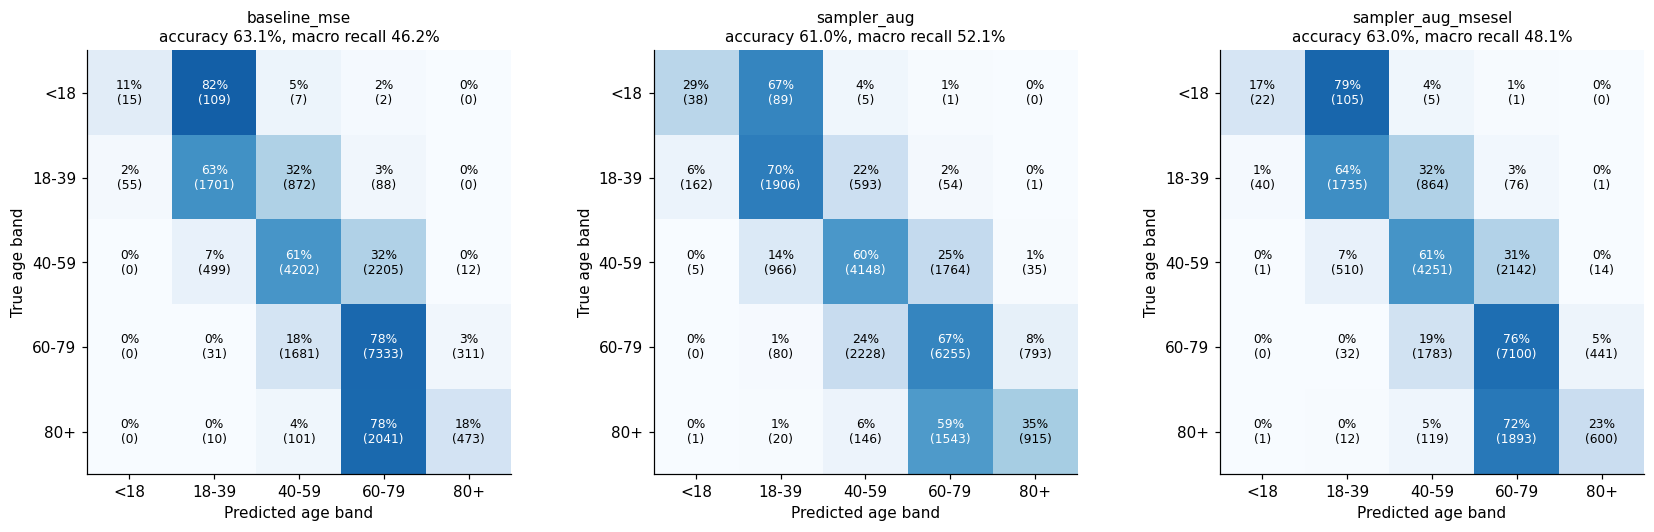

In [3]:
# ---- CELL 3: confusion matrices ----
fig, axes = plt.subplots(1, len(EVAL_RUNS), figsize=(5.2*len(EVAL_RUNS), 4.8), squeeze=False)
for ax, n in zip(axes[0], EVAL_RUNS):
    cm = conf[n]; pct = 100 * cm.values / cm.sum(axis=1).values.clip(min=1)[:, None]
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{pct[i,j]:.0f}%\n({cm.values[i,j]})", ha="center", va="center", fontsize=8,
                    color="white" if pct[i, j] > 55 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels(LABELS); ax.set_yticks(range(5)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted age band"); ax.set_ylabel("True age band"); ax.grid(False)
    ax.set_title(f"{n}\naccuracy {summary.loc[n, 'accuracy_%']:.1f}%, macro recall {summary.loc[n, 'macro_recall_%']:.1f}%", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=200); plt.show()
for n in EVAL_RUNS: conf[n].to_csv(EVAL_DIR / f"confusion_counts_{n}.csv")

## 3. Within-tolerance accuracy (±k years) by shot group

In [4]:
# ---- CELL 4: within-tolerance accuracy ----
rows = []
for n, d in preds.items():
    for g in ["all"] + GROUPS:
        m = np.ones(len(d), bool) if g == "all" else (d["group"] == g).to_numpy()
        e = d["err"].abs().to_numpy()[m]
        rows.append({"run": n, "group": g, "n": int(m.sum()),
                     **{f"within_{k}y_%": round(100*float((e <= k).mean()), 2) for k in (3, 5, 10)}})
tol = pd.DataFrame(rows); tol.to_csv(EVAL_DIR / "within_tolerance.csv", index=False)
for k in (3, 5, 10):
    t = tol.pivot(index="run", columns="group", values=f"within_{k}y_%")[["all"] + GROUPS]
    print(f"\nAccuracy within ±{k} years (%)"); display(t) if "display" in globals() else print(t)


Accuracy within ±3 years (%)
group                 all   many  median    few
run                                            
baseline_mse        26.50  27.10   20.49   2.78
sampler_aug         25.71  25.57   28.98  13.19
sampler_aug_msesel  26.31  26.94   19.37   6.94

Accuracy within ±5 years (%)
group                 all   many  median    few
run                                            
baseline_mse        42.81  43.65   34.11  11.11
sampler_aug         40.85  40.69   44.42  28.47
sampler_aug_msesel  42.16  43.16   31.09  12.50

Accuracy within ±10 years (%)
group                 all   many  median    few
run                                            
baseline_mse        73.05  74.35   58.04  38.19
sampler_aug         70.80  70.72   72.56  63.89
sampler_aug_msesel  72.68  73.84   60.07  34.72


## 4. Figures

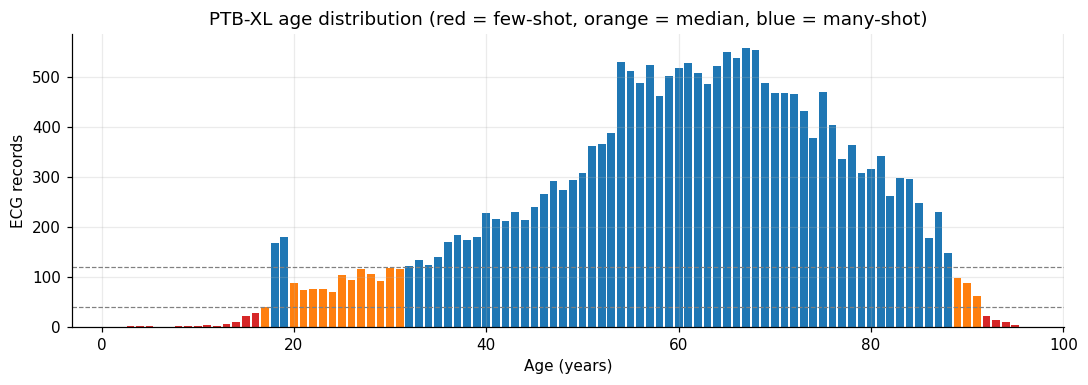

In [5]:
# ---- CELL 5: age distribution with shot groups ----
f = REPORT_DIR / "exact_age_frequency_counts.csv"
if f.exists():
    ac = pd.read_csv(f)
    col = ac["shot_group"].map({"few": "#d62728", "median": "#ff7f0e", "many": "#1f77b4"})
    plt.figure(figsize=(10, 3.6)); plt.bar(ac["age"], ac["records"], color=col)
    plt.axhline(40, ls="--", c="gray", lw=.8); plt.axhline(120, ls="--", c="gray", lw=.8)
    plt.xlabel("Age (years)"); plt.ylabel("ECG records"); plt.title("PTB-XL age distribution (red = few-shot, orange = median, blue = many-shot)")
    plt.tight_layout(); plt.savefig(FIG_DIR / "age_distribution.png", dpi=200); plt.show()
else:
    print("Missing", f, "- run section 4 of the main notebook first.")

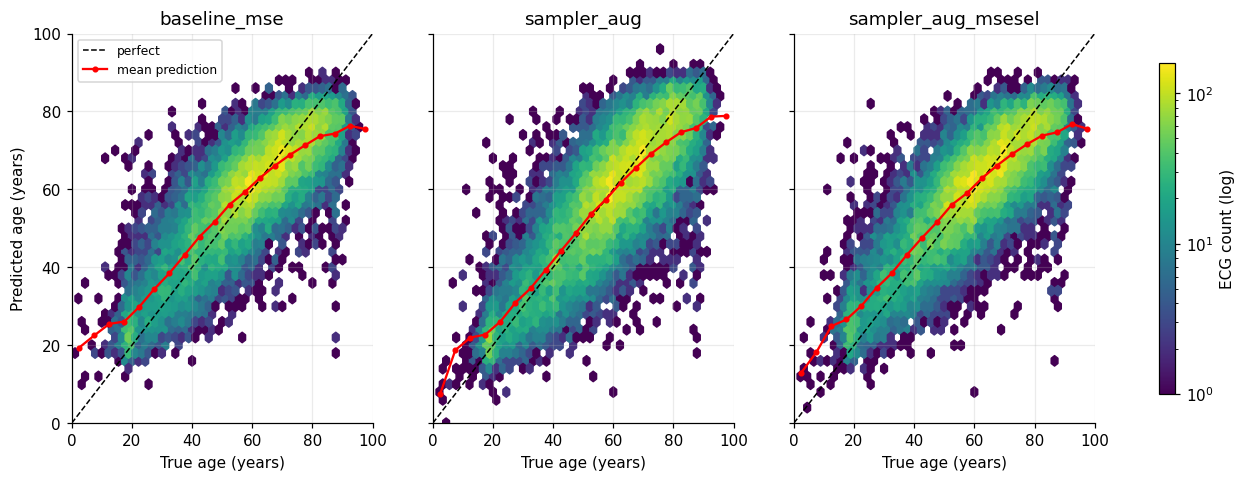

In [6]:
# ---- CELL 6: true vs predicted age (density), with mean prediction per true-age bin ----
fig, axes = plt.subplots(1, len(EVAL_RUNS), figsize=(5*len(EVAL_RUNS), 4.6), squeeze=False, sharex=True, sharey=True)
edges = np.arange(0, 105, 5); mid = (edges[:-1] + edges[1:]) / 2
for ax, n in zip(axes[0], EVAL_RUNS):
    d = preds[n]
    hb = ax.hexbin(d["age"], d["pred"], gridsize=45, bins="log", mincnt=1, cmap="viridis", extent=(0, 100, 0, 100))
    ax.plot([0, 100], [0, 100], "k--", lw=1, label="perfect")
    mp = d.groupby(pd.cut(d["age"], edges, right=False), observed=False)["pred"].mean().values
    ax.plot(mid, mp, color="red", marker="o", ms=3, lw=1.5, label="mean prediction")
    ax.set_xlabel("True age (years)"); ax.set_title(n); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
axes[0][0].set_ylabel("Predicted age (years)"); axes[0][0].legend(loc="upper left", fontsize=8)
fig.colorbar(hb, ax=axes[0].tolist(), label="ECG count (log)", shrink=.85)
plt.savefig(FIG_DIR / "true_vs_predicted.png", dpi=200, bbox_inches="tight"); plt.show()

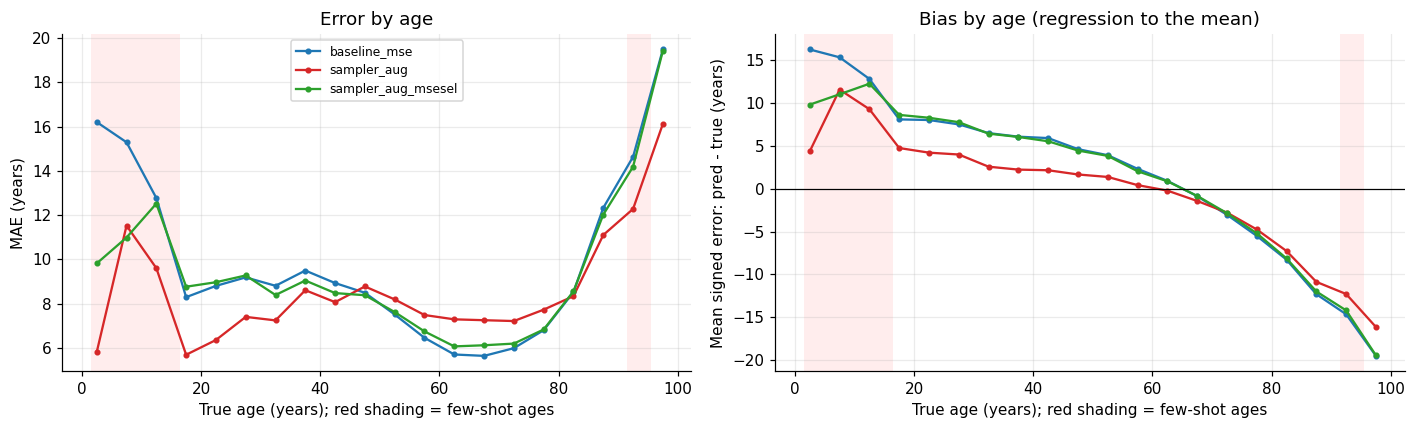

In [7]:
# ---- CELL 7: MAE and bias versus true age (5-year bins); few-shot ages shaded ----
d0 = preds[EVAL_RUNS[0]]
few_ages = sorted(d0.loc[d0["group"] == "few", "age"].unique())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, d in preds.items():
    g = d.groupby(pd.cut(d["age"], edges, right=False), observed=False)
    ax[0].plot(mid, g["err"].apply(lambda s: s.abs().mean()).values, marker="o", ms=3, label=n, color=COLORS[n])
    ax[1].plot(mid, g["err"].mean().values, marker="o", ms=3, label=n, color=COLORS[n])
for a in ax:
    for fa in few_ages: a.axvspan(fa - .5, fa + .5, color="red", alpha=.07, lw=0)
ax[0].set_ylabel("MAE (years)"); ax[1].set_ylabel("Mean signed error: pred - true (years)"); ax[1].axhline(0, c="k", lw=.8)
for a in ax: a.set_xlabel("True age (years); red shading = few-shot ages")
ax[0].set_title("Error by age"); ax[1].set_title("Bias by age (regression to the mean)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "error_and_bias_by_age.png", dpi=200); plt.show()

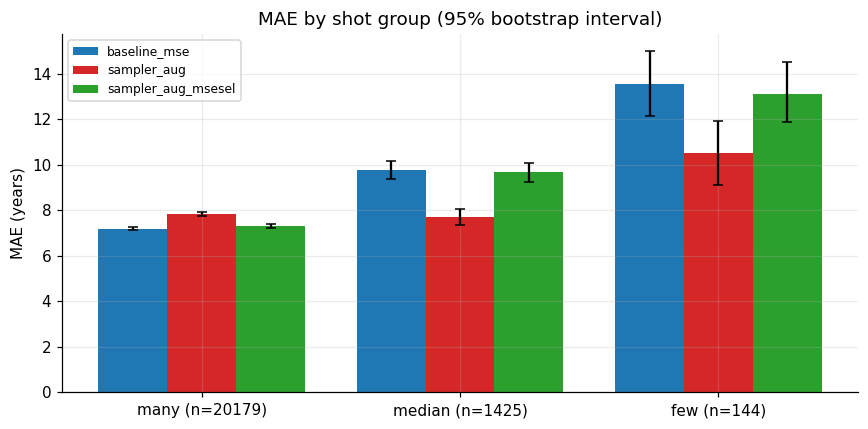

In [8]:
# ---- CELL 8: MAE by shot group with 95% bootstrap intervals ----
rng = np.random.default_rng(0); B = 1000
fig, ax = plt.subplots(figsize=(8, 4)); w = 0.8 / len(EVAL_RUNS)
for i, n in enumerate(EVAL_RUNS):
    d = preds[n]; mae, lo, hi = [], [], []
    for g in GROUPS:
        e = d.loc[d["group"] == g, "err"].abs().to_numpy()
        bs = e[rng.integers(0, len(e), (B, len(e)))].mean(axis=1)
        mae.append(e.mean()); lo.append(e.mean() - np.percentile(bs, 2.5)); hi.append(np.percentile(bs, 97.5) - e.mean())
    ax.bar(np.arange(3) + i*w, mae, w, yerr=[lo, hi], capsize=3, label=n, color=COLORS[n])
ax.set_xticks(np.arange(3) + 0.4 - w/2); ax.set_xticklabels([f"{g} (n={int((preds[EVAL_RUNS[0]]['group']==g).sum())})" for g in GROUPS])
ax.set_ylabel("MAE (years)"); ax.set_title("MAE by shot group (95% bootstrap interval)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "mae_by_shot_group.png", dpi=200); plt.show()

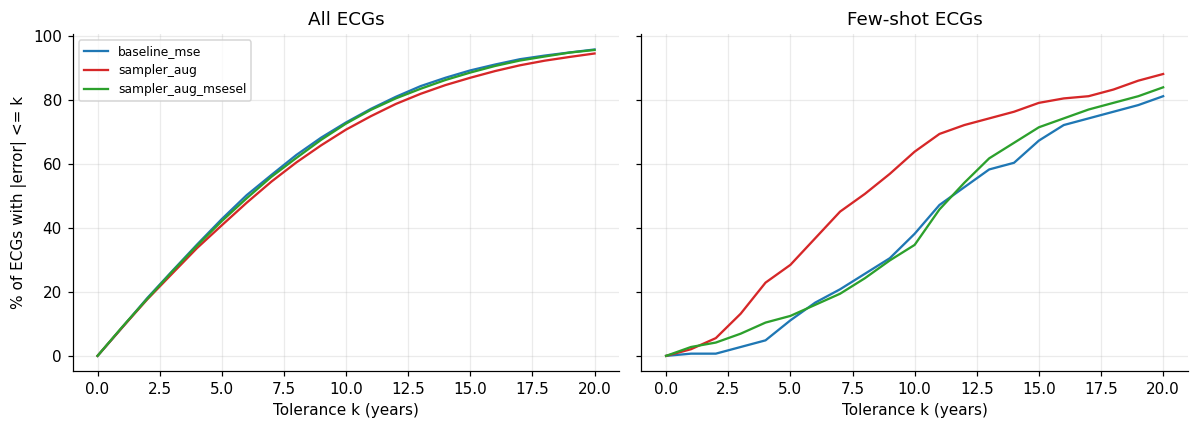

In [9]:
# ---- CELL 9: cumulative score curves (accuracy within k years) ----
ks = np.arange(0, 21)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (title, g) in zip(ax, [("All ECGs", None), ("Few-shot ECGs", "few")]):
    for n, d in preds.items():
        e = d["err"].abs().to_numpy() if g is None else d.loc[d["group"] == g, "err"].abs().to_numpy()
        a.plot(ks, [100 * (e <= k).mean() for k in ks], label=n, color=COLORS[n])
    a.set_title(title); a.set_xlabel("Tolerance k (years)")
ax[0].set_ylabel("% of ECGs with |error| <= k"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "cumulative_score.png", dpi=200); plt.show()

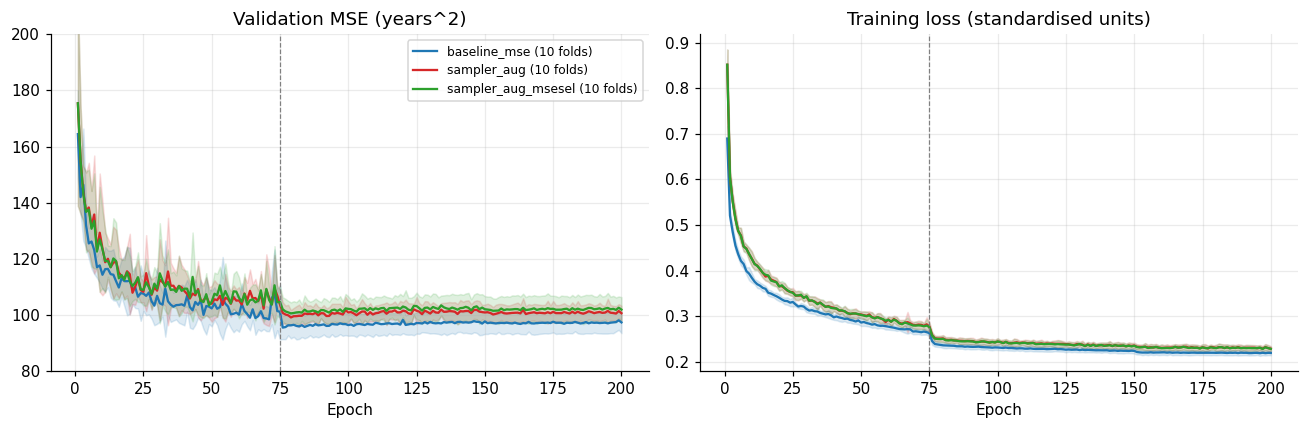

In [10]:
# ---- CELL 10: training curves (mean +/- std over folds) ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); found = False
for n in EVAL_RUNS:
    hs = [pd.read_csv(p) for p in sorted(EVAL_DIR.glob(f"lite_{n}_fold*_history.csv"))]
    if not hs: continue
    found = True; L = min(len(h) for h in hs)
    for a, col in zip(ax, ["val_mse", "train_loss"]):
        M = np.stack([h[col].to_numpy()[:L] for h in hs]); x = np.arange(1, L + 1)
        a.plot(x, M.mean(0), label=f"{n} ({len(hs)} folds)", color=COLORS[n])
        a.fill_between(x, M.mean(0) - M.std(0), M.mean(0) + M.std(0), color=COLORS[n], alpha=.15)
if found:
    ax[0].set_title("Validation MSE (years^2)"); ax[1].set_title("Training loss (standardised units)")
    ax[0].set_ylim(80, 200)
    for a in ax: a.axvline(LR_STEP_PLOT, ls="--", c="gray", lw=.8); a.set_xlabel("Epoch")
    ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "training_curves.png", dpi=200); plt.show()
else:
    print("No *_history.csv files found in", EVAL_DIR)

## 5. Everything that was saved
Figures are in `runs/<folder>/figures/`, tables (`band_metrics_*.csv`, `within_tolerance.csv`, `confusion_counts_*.csv`) in the run folder.

In [11]:
# ---- CELL 11: list saved files ----
for p in sorted(FIG_DIR.glob("*.png")): print("figure:", p)
for p in sorted(EVAL_DIR.glob("band_metrics_*.csv")) + sorted(EVAL_DIR.glob("confusion_counts_*.csv")) + [EVAL_DIR / "within_tolerance.csv"]:
    print("table :", p)

figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\age_distribution.png
figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\confusion_matrices.png
figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\cumulative_score.png
figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\error_and_bias_by_age.png
figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\mae_by_shot_group.png
figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\training_curves.png
figure: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\figures\true_vs_predicted.png
table : C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\band_metrics_overall.csv
table : C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\band_metrics_per_band.csv
table : C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\confusion_counts_baseline_ms